# Lecture 4: Data Representations for SciML (with solutions)

The same physical field can be stored in many ways. Each choice decides what a model sees and what it has to learn.
Three parts, one for each part of today's lecture:

1. **Resolution**: downsample BubbleML frames from 512 × 512 to 64 × 64 by keeping every 8th value and by averaging, and compare their spectra.
2. **POD**: compute the modes of the heat data and of BubbleML temperature and reconstruct frames with a few modes.
3. **Predicting the change**: retrain the Lecture 1 `SmallCNN` on the heat data with a standardized increment and compare rollouts.

In [1]:
import os
import urllib.request
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
rng = np.random.default_rng(0)

# the Lecture 1 BubbleML files (downloaded again if missing)
DATA_DIR = "../data/bubbleml"
URL = "https://raw.githubusercontent.com/HPCForge/BubbleML/main/examples/"
os.makedirs(DATA_DIR, exist_ok=True)
for f in ["Twall-100.hdf5", "Twall-106.hdf5"]:
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, os.path.join(DATA_DIR, f))

# temperature colormap from Lecture 1 (https://github.com/therml-ai/boiling-viz), for nondimensional temperature in [0, 1]
from matplotlib.colors import LinearSegmentedColormap
temp_cmap = LinearSegmentedColormap.from_list("temp_green", list(zip(
    [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.134, 0.167, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ["#0000FF", "#0443FF", "#0E7AFF", "#16B4FF", "#1FF1FF", "#21FFD3", "#22FF9B", "#22FF67", "#22FF15", "#29FF06",
     "#45FF07", "#6DFF08", "#9EFF09", "#D4FF0A", "#FEF30A", "#FEB709", "#FD7D08", "#FC4908", "#FC1407", "#FB0007"])))

def load_temperature(twall):
    with h5py.File(os.path.join(DATA_DIR, f"Twall-{twall}.hdf5"), "r") as f:
        return f["temperature"][:].astype(np.float64)       # (time, y, x), nondimensional, 0 = bulk liquid, 1 = heater

temp106 = load_temperature(106)
print("Twall = 106 °C temperature:", temp106.shape)

Using device: cpu
Twall = 106 °C temperature: (201, 48, 48)


---
## Part 1: Downsampling, by keeping values or by averaging

For this part we use 25 temperature frames from BubbleML_2 at full resolution, 512 × 512
(Twall = 106 °C, t = 150 to 169, 0.8 apart, stored as nondimensional temperature in float16).
The file `bubbleml2_Twall106_512_t150-170.npz` is in the course `data/bubbleml` folder.

We reduce each frame to 64 × 64 in two ways:

* **stride**: keep one value from each 8 × 8 block of cells, `u[o::8, o::8]`. There are 8 choices of the offset `o` in each direction.
* **average**: replace each 8 × 8 block by its mean.

Recall Nyquist from the lecture: a 64 × 64 grid can represent wavenumbers up to 32.
Anything finer in the 512 × 512 field has to go somewhere.

BubbleML_2 temperature: (25, 512, 512)   times 150.0 to 169.20000000000002


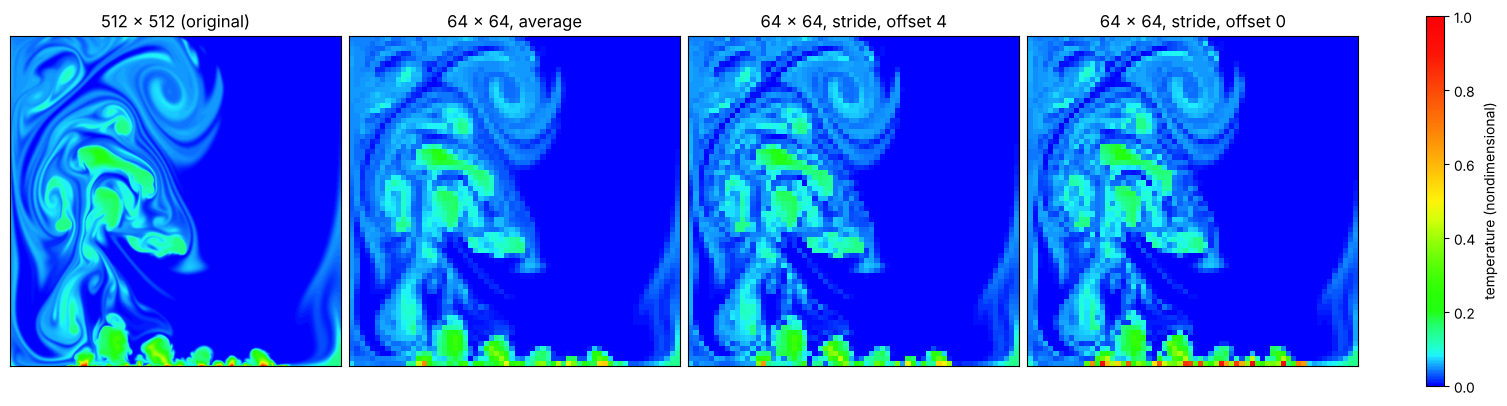

In [2]:
hires = np.load(os.path.join(DATA_DIR, "bubbleml2_Twall106_512_t150-170.npz"))
temp512 = hires["temperature"].astype(np.float64)        # (25, 512, 512)
print("BubbleML_2 temperature:", temp512.shape, "  times", hires["t"][0], "to", hires["t"][-1])

f = 8                       # downsampling factor: 512 -> 64
n_coarse = 512 // f

def stride(u, offset):
    return u[..., offset::f, offset::f]

def average(u):
    return u.reshape(*u.shape[:-2], n_coarse, f, n_coarse, f).mean(axis=(-3, -1))

t = 12
panels = [(temp512[t], "512 × 512 (original)"),
          (average(temp512[t]), "64 × 64, average"),
          (stride(temp512[t], 4), "64 × 64, stride, offset 4"),
          (stride(temp512[t], 0), "64 × 64, stride, offset 0")]
fig, axes = plt.subplots(1, 4, figsize=(15, 4), layout="constrained")
for ax, (img, title) in zip(axes, panels):
    im = ax.imshow(img, cmap=temp_cmap, vmin=0, vmax=1, origin="lower")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, label="temperature (nondimensional)")
plt.show()

The strided frames look sharper than the average, with thin plumes and bubble edges kept as single bright or dark cells.
Offset 0 keeps the bottom row of cells, the thin hot layer on the heater, so the bottom row of the coarse grid is hotter than in the average.

To see where the difference comes from, compare **energy spectra**: for each wavenumber $k$, the energy of the Fourier modes with $|k| \approx k$
(the same radially summed $|\mathrm{FFT}|^2$ as on the slide), averaged over the 25 frames.
As on the slide, we plot the energy of each 64 × 64 version divided by the energy of the 512 × 512 original at the same wavenumber.
A ratio of 1 means that wavenumber is kept as it was.

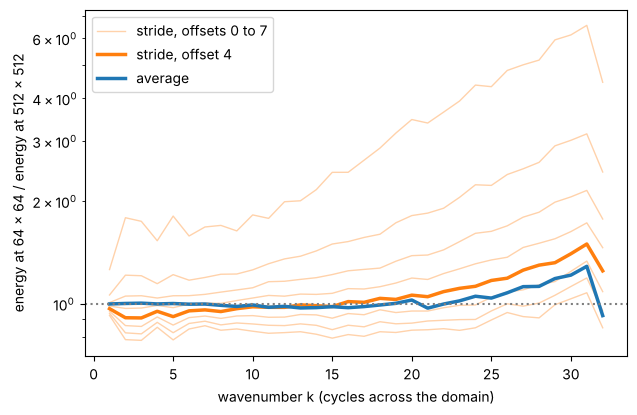

share of the energy above k = 32 in the original: 15%


In [3]:
def spectrum(u):
    # radially summed |FFT|^2 per integer wavenumber, averaged over frames; u has shape (frames, n, n)
    n = u.shape[-1]
    uhat = np.fft.fft2(u - u.mean(axis=(-2, -1), keepdims=True)) / n**2
    energy = np.abs(uhat)**2
    k = np.fft.fftfreq(n) * n
    kx, ky = np.meshgrid(k, k)
    kr = np.rint(np.hypot(kx, ky)).astype(int)
    return np.array([energy[:, kr == j].sum(axis=-1).mean() for j in range(n // 2 + 1)])

E_full = spectrum(temp512)
k = np.arange(1, n_coarse // 2 + 1)
ratio = lambda E: E[1:] / E_full[1:n_coarse // 2 + 1]

plt.figure(figsize=(7, 4.5))
for o in range(f):
    plt.plot(k, ratio(spectrum(stride(temp512, o))), color="tab:orange", lw=1, alpha=0.35,
             label="stride, offsets 0 to 7" if o == 0 else None)
plt.plot(k, ratio(spectrum(stride(temp512, 4))), color="tab:orange", lw=2.5, label="stride, offset 4")
plt.plot(k, ratio(spectrum(average(temp512))), color="tab:blue", lw=2.5, label="average")
plt.axhline(1, color="gray", ls=":")
plt.yscale("log")
plt.xlabel("wavenumber k (cycles across the domain)"); plt.ylabel("energy at 64 × 64 / energy at 512 × 512")
plt.legend(); plt.show()


print(f"share of the energy above k = {n_coarse // 2} in the original: {E_full[n_coarse // 2 + 1:].sum() / E_full[1:].sum():.0%}")

**What to observe**

* The average stays close to 1 up to about $k = 20$, then rises to about 1.25 just below the Nyquist wavenumber, 32.
  An 8 × 8 block average is a simple low-pass filter: it removes most of the energy above 32, and lets a little of what lies just above 32 through.
* The strided spectra rise above 1 toward $k = 32$. That extra energy came from wavenumbers above 32, which the 64 × 64 grid cannot hold,
  so it folds back onto lower wavenumbers (aliasing).
* How much folds back depends on the offset, that is, which cell of each block you happen to keep. Offset 0 sits on the heater row and is far off;
  some offsets fall below 1. The average has one spectra.

---
## Part 2: POD of the heat data and of BubbleML

Recall from the lecture: the snapshots, minus their mean, form the columns of a matrix $X$. Compute the SVD,

$$X = [\,u_1 - \bar u,\; \dots,\; u_N - \bar u\,] = U \Sigma V^\top .$$

The columns of $U$ are the POD modes $\varphi_k$, and the singular values $\sigma_k$ indicate how much each mode contributes.
To compress a field, keep the first $r$ modes $U_r$:

$$a = U_r^\top (u - \bar u), \qquad \hat u = \bar u + U_r\, a .$$


heat      250 snapshots:  90% of the energy needs   2 modes,  99% needs   4
BubbleML  200 snapshots:  90% of the energy needs  51 modes,  99% needs 147


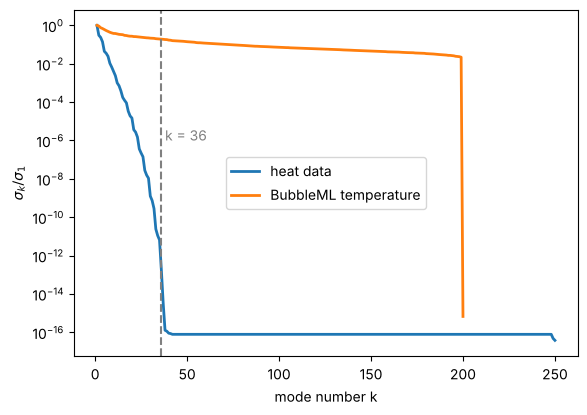

In [4]:
N, alpha, dt, T, K = 48, 1.0, 5e-4, 100, 6       # same settings as Lecture 1
x = np.linspace(0, 1, N)
X, Y = np.meshgrid(x, x)

def heat_trajectory(K=K):
    u = np.zeros((T + 1, N, N))
    t = np.arange(T + 1)[:, None, None] * dt
    for m in range(1, K + 1):
        for n in range(1, K + 1):
            a = rng.normal() / (m**2 + n**2)
            u += a * np.sin(m * np.pi * X) * np.sin(n * np.pi * Y) * np.exp(-alpha * np.pi**2 * (m**2 + n**2) * t)
    return u

heat_train64 = np.stack([heat_trajectory() for _ in range(100)])      # same seed and order as Lecture 1
heat_test64 = np.stack([heat_trajectory() for _ in range(20)])
heat_train, heat_test = heat_train64.astype(np.float32), heat_test64.astype(np.float32)

def pod(snapshots):
    # snapshots: (count, ny, nx). Returns mean, modes U (columns), singular values S
    Xs = snapshots.reshape(len(snapshots), -1).T
    mean = Xs.mean(axis=1, keepdims=True)
    U, S, _ = np.linalg.svd(Xs - mean, full_matrices=False)
    return mean[:, 0], U, S

heat_snap = heat_train64[:3, 1:].reshape(-1, N, N)[:250]     # 250 consecutive frames from 3 trajectories (as on the slide)
bubble_snap = temp106[1:]                                     # 200 frames, 1.0 apart
heat_mean, heat_U, heat_S = pod(heat_snap)
bubble_mean, bubble_U, bubble_S = pod(bubble_snap)

def modes_for(S, frac):
    energy = np.cumsum(S**2) / np.sum(S**2)
    return int(np.searchsorted(energy, frac) + 1)

for name, S in [("heat", heat_S), ("BubbleML", bubble_S)]:
    print(f"{name:9s} {len(S)} snapshots:  90% of the energy needs {modes_for(S, 0.9):3d} modes,  99% needs {modes_for(S, 0.99):3d}")

plt.figure(figsize=(6.5, 4.5))
plt.semilogy(np.arange(1, len(heat_S) + 1), heat_S / heat_S[0], lw=2, label="heat data")
plt.semilogy(np.arange(1, len(bubble_S) + 1), bubble_S / bubble_S[0], lw=2, label="BubbleML temperature")
plt.axvline(36, color="gray", ls="--"); plt.text(38, 1e-6, "k = 36", color="gray")
plt.xlabel("mode number k"); plt.ylabel(r"$\sigma_k / \sigma_1$"); plt.legend(); plt.show()

**What to observe**

* The heat data reach round-off after 36 modes. Every snapshot is a combination of the $6 \times 6$ sine modes $\sin(m\pi x)\sin(n\pi y)$, $m, n \le 6$, so the snapshots span 36 dimensions at most.
* The BubbleML singular values fall slowly. Bubbles and plumes move, and a moving feature needs many fixed modes.
  The drop at the end is the number of snapshots: 200 snapshots minus their mean span at most 199 dimensions.

Now reconstruct one frame of each (a frame from the snapshot set) with $r = 5$, $20$ and $50$ modes.

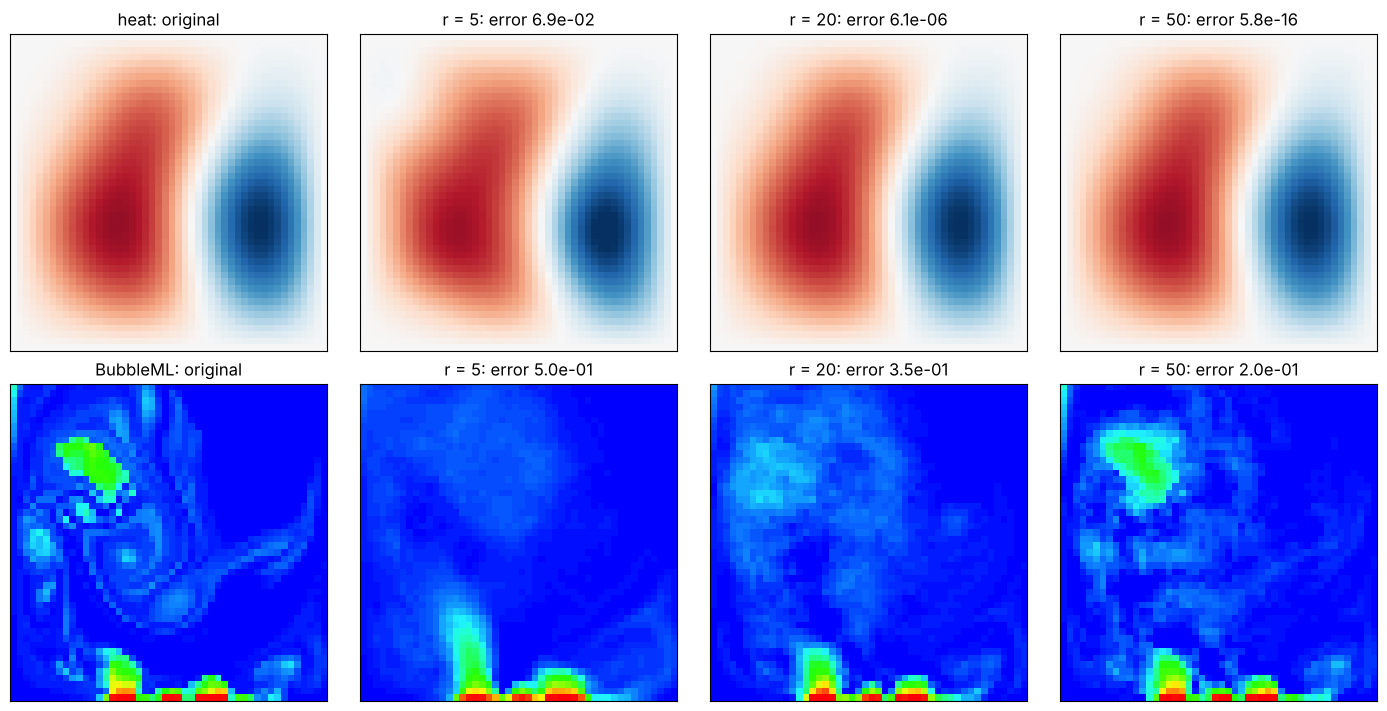

In [5]:
def reconstruct(u, mean, U, r):
    a = U[:, :r].T @ (u.ravel() - mean)            # r coefficients
    return (mean + U[:, :r] @ a).reshape(u.shape)

def relative_error(pred, true):
    return np.linalg.norm(pred - true) / np.linalg.norm(true)

ranks = [5, 20, 50]
cases = [("heat", heat_snap[30], heat_mean, heat_U, "RdBu_r"),
         ("BubbleML", bubble_snap[100], bubble_mean, bubble_U, temp_cmap)]
fig, axes = plt.subplots(2, len(ranks) + 1, figsize=(14, 7), layout="constrained")
for row, (name, u, mean, U, cmap) in enumerate(cases):
    lo, hi = (-np.abs(u).max(), np.abs(u).max()) if name == "heat" else (0, 1)
    axes[row, 0].imshow(u, cmap=cmap, vmin=lo, vmax=hi, origin="lower")
    axes[row, 0].set_title(f"{name}: original")
    for col, r in enumerate(ranks, start=1):
        rec = reconstruct(u, mean, U, r)
        axes[row, col].imshow(rec, cmap=cmap, vmin=lo, vmax=hi, origin="lower")
        axes[row, col].set_title(f"r = {r}: error {relative_error(rec, u):.1e}")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

**What to observe:** the heat frame is exact to round-off once $r \ge 36$, while the BubbleML frame still shows a visible error with 50 modes.
POD works well when the data lie near a low-dimensional linear subspace and poorly when features move.

---
## Part 3: Predicting a standardized increment

In Lecture 1, `SmallCNN.forward` returned `x[:, :1] + self.net(x)`: the current field plus a learned change.
That is forward Euler with a learned right-hand side and the network is trained on the increment $\Delta u = u_{n+1} - u_n$.

How big is that increment compared with the field?

In [6]:
du = heat_train[:, 1:] - heat_train[:, :-1]
mu_u, sigma_u = heat_train[:, :-1].mean(), heat_train[:, :-1].std()
mu_du, sigma_du = du.mean(), du.std()
print(f"u : mean {mu_u:+.2e}   std {sigma_u:.2e}")
print(f"Δu: mean {mu_du:+.2e}   std {sigma_du:.2e}   ({sigma_du / sigma_u:.1%} of the std of u)")

u : mean -4.12e-03   std 1.73e-01
Δu: mean +5.23e-05   std 3.59e-03   (2.1% of the std of u)


The network has to output values about 50 times smaller than its input. We standardize the input with $\mu_u, \sigma_u$
and the increment with $\mu_\Delta, \sigma_\Delta$, all computed from the training set:

$$\hat u_{n+1} = u_n + \mu_\Delta + \sigma_\Delta\, f(\tilde u_n; \theta), \qquad \tilde u_n = \frac{u_n - \mu_u}{\sigma_u}.$$

The loss is still MSE between $\hat u_{n+1}$ and $u_{n+1}$, as in Lecture 1. The scaling sits outside the network, so the network outputs values of order 1.

In [7]:
class SmallCNN(nn.Module):
    # Lecture 1 model: predicts the change and adds it to the current field
    def __init__(self, in_channels=1, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.GELU(),
            nn.Conv2d(hidden, 1, 3, padding=1),
        )

    def forward(self, x):
        return x[:, :1] + self.net(x)

class StandardizedCNN(SmallCNN):
    # same network; standardized input, and the output is scaled to the size of the increment
    def __init__(self, mu_u, sigma_u, mu_du, sigma_du, **kwargs):
        super().__init__(**kwargs)
        self.mu_u, self.sigma_u, self.mu_du, self.sigma_du = float(mu_u), float(sigma_u), float(mu_du), float(sigma_du)

    def forward(self, x):
        x_std = (x - self.mu_u) / self.sigma_u
        return x[:, :1] + self.mu_du + self.sigma_du * self.net(x_std)

def to_pairs(trajs):
    inputs = trajs[:, :-1].reshape(-1, 1, N, N)
    targets = trajs[:, 1:].reshape(-1, 1, N, N)
    return TensorDataset(torch.from_numpy(inputs), torch.from_numpy(targets))

def train(model, loader, epochs, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        total = 0.0
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            loss = F.mse_loss(model(inputs), targets)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item()
        print(f"epoch {epoch + 1:2d}   loss {total / len(loader):.2e}")
    return model

heat_loader = DataLoader(to_pairs(heat_train), batch_size=64, shuffle=True)

torch.manual_seed(0)
print("Lecture 1 model")
baseline = train(SmallCNN(), heat_loader, epochs=5)
torch.manual_seed(0)
print("\nstandardized increment")
standardized = train(StandardizedCNN(mu_u, sigma_u, mu_du, sigma_du), heat_loader, epochs=5)

Lecture 1 model


epoch  1   loss 9.49e-06


epoch  2   loss 3.86e-06


epoch  3   loss 3.22e-06


epoch  4   loss 2.79e-06


...

epoch  1   loss 6.80e-06


epoch  2   loss 4.29e-06


epoch  3   loss 2.32e-06


epoch  4   loss 1.49e-06


epoch  5   loss 1.04e-06


Both models use the same network, the same initial weights (same seed), the same data and the same 5 epochs.
Now compare one-step errors and rollouts on the 20 test trajectories.

Lecture 1 model          one-step relative error 1.03e-02


standardized increment   one-step relative error 5.54e-03


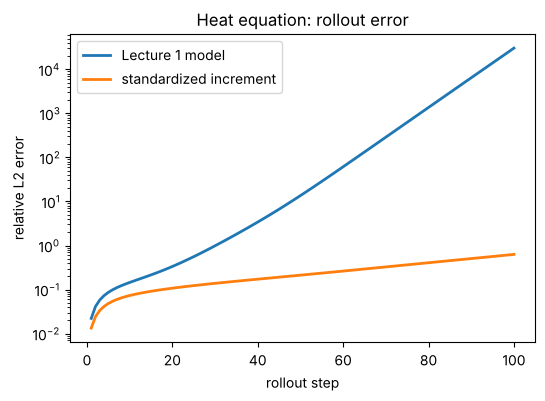

In [8]:
def rollout_errors(model, trajs):
    model.eval()
    errors = []
    with torch.no_grad():
        for traj in trajs:
            u = torch.from_numpy(traj[0]).reshape(1, 1, N, N).to(device)
            preds = []
            for n in range(T):
                u = model(u)
                preds.append(u.cpu().numpy()[0, 0])
            errors.append([relative_error(preds[n], traj[n + 1]) for n in range(T)])
    return np.mean(errors, axis=0)

def one_step_error(model, trajs):
    model.eval()
    with torch.no_grad():
        inputs = torch.from_numpy(trajs[:, :-1].reshape(-1, 1, N, N)).to(device)
        pred = model(inputs).cpu().numpy()
    return relative_error(pred, trajs[:, 1:].reshape(-1, 1, N, N))

for name, model in [("Lecture 1 model", baseline), ("standardized increment", standardized)]:
    print(f"{name:24s} one-step relative error {one_step_error(model, heat_test):.2e}")

steps = np.arange(1, T + 1)
plt.figure(figsize=(6, 4))
plt.semilogy(steps, rollout_errors(baseline, heat_test), lw=2, label="Lecture 1 model")
plt.semilogy(steps, rollout_errors(standardized, heat_test), lw=2, label="standardized increment")
plt.xlabel("rollout step"); plt.ylabel("relative L2 error"); plt.title("Heat equation: rollout error")
plt.legend(); plt.show()

**What to observe**

* The standardized model has the lower one-step error, about half that of the Lecture 1 model in our runs.
* Five epochs is short, and the rollout changes from run to run. In most of our runs the Lecture 1 model's rollout blew up (error above 100%),
  while the standardized model stayed bounded. Try another seed: change `torch.manual_seed(0)` to `1` or `2` before training.
* Late in the rollout the field has decayed toward zero, so the relative error grows for both models.

---
## Exercises

1. **Coarser grid.** Repeat Part 1 with `f = 16` (a 32 × 32 grid). How does the aliased energy change, and why?
2. **POD across conditions.** Compute POD modes from the Twall = 100 °C file and use them to reconstruct the frame from the 106 °C file used in Part 2.
   Compare the errors with those from the 106 °C modes. What does this say about using POD modes from one run on another?
3. **Unseen frequencies, again.** In Lecture 1, Exercise 3 trained on `K = 3` and tested on `K = 6`. Compute POD modes from `K = 3` heat data
   (use `heat_trajectory(K=3)`) and reconstruct `K = 6` test frames with them. Plot the error against time along a trajectory. Where does it concentrate, and why?
4. **Standardized increment for BubbleML.** For the Lecture 1 BubbleML temperature, the std of $\Delta T$ is about 56% of the std of $T$.
   Train the BubbleML model of Lecture 1 with and without the standardized increment. Do you expect as large a difference as for the heat data?

---
## Solutions

### Exercise 1: coarser grid, `f = 16`

The functions `stride` and `average` use the global `f` and `n_coarse`, so we set them and rerun the Part 1 comparison.

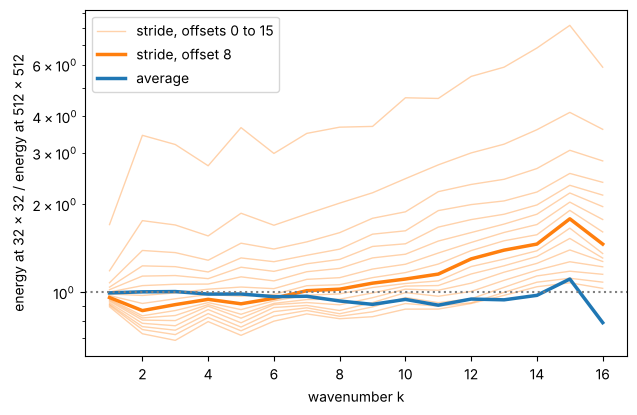

64 x 64 grid: share of the original energy above its Nyquist wavenumber 32: 14.9%
32 x 32 grid: share of the original energy above its Nyquist wavenumber 16: 26.9%


In [9]:
f, n_coarse = 16, 512 // 16           # 32 x 32 grid, Nyquist wavenumber 16
k32 = np.arange(1, n_coarse // 2 + 1)
ratio32 = lambda E: E[1:] / E_full[1:n_coarse // 2 + 1]
plt.figure(figsize=(7, 4.5))
for o in range(f):
    plt.plot(k32, ratio32(spectrum(stride(temp512, o))), color="tab:orange", lw=1, alpha=0.35, label="stride, offsets 0 to 15" if o == 0 else None)
plt.plot(k32, ratio32(spectrum(stride(temp512, 8))), color="tab:orange", lw=2.5, label="stride, offset 8")
plt.plot(k32, ratio32(spectrum(average(temp512))), color="tab:blue", lw=2.5, label="average")
plt.axhline(1, color="gray", ls=":"); plt.yscale("log")
plt.xlabel("wavenumber k"); plt.ylabel("energy at 32 × 32 / energy at 512 × 512"); plt.legend(); plt.show()
for n_c in (64, 32):
    print(f"{n_c} x {n_c} grid: share of the original energy above its Nyquist wavenumber {n_c // 2}: "
          f"{E_full[n_c // 2 + 1:].sum() / E_full[1:].sum():.1%}")
f, n_coarse = 8, 512 // 8             # restore the Part 1 settings

**Answer.** At 32 × 32 the Nyquist wavenumber is 16, and 27% of the energy of the original lies above it (15% lies above 32, the limit of the 64 × 64 grid). There is more energy to fold back, so aliasing is stronger: most strided spectra rise well above 1, and the spread between offsets is much wider than at 64 × 64.

The block average stays close to 1 up to about $k = 14$. Averaging over 16 × 16 blocks removes most of the energy above 16 before it can fold back.

### Exercise 2: POD modes from another run

Modes, mean and singular values from the 100 °C file; reconstruct the same 106 °C frame as in Part 2 (`bubble_snap[100]`) with both sets of modes.

   r   106 °C modes   100 °C modes
   5          0.503          0.645
  20          0.354          0.497
  50          0.196          0.437
 100          0.097          0.398
 199          0.000          0.363
r = 0 (mean only):   106 °C mean 0.629   100 °C mean 0.673


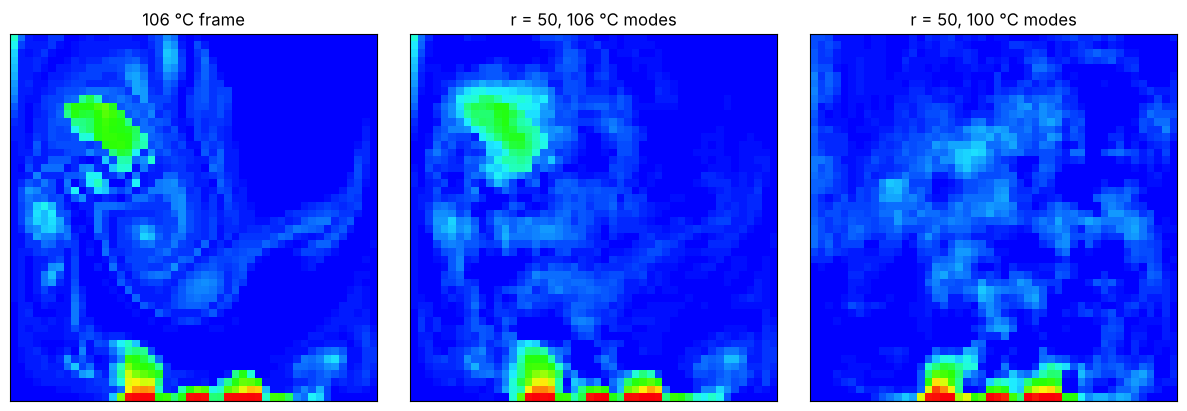

In [10]:
temp100 = load_temperature(100)
m100, U100, S100 = pod(temp100[1:])
u = bubble_snap[100]
print(f"{'r':>4s}  {'106 °C modes':>13s}  {'100 °C modes':>13s}")
for r in [5, 20, 50, 100, 199]:
    print(f"{r:4d}  {relative_error(reconstruct(u, bubble_mean, bubble_U, r), u):13.3f}  {relative_error(reconstruct(u, m100, U100, r), u):13.3f}")
print(f"r = 0 (mean only):   106 °C mean {relative_error(bubble_mean.reshape(u.shape), u):.3f}   100 °C mean {relative_error(m100.reshape(u.shape), u):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, (img, title) in zip(axes, [(u, "106 °C frame"), (reconstruct(u, bubble_mean, bubble_U, 50), "r = 50, 106 °C modes"),
                                   (reconstruct(u, m100, U100, 50), "r = 50, 100 °C modes")]):
    ax.imshow(img, cmap=temp_cmap, vmin=0, vmax=1, origin="lower"); ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.show()

**Answer.** The 106 °C modes reconstruct the frame much better at every rank. With the 100 °C modes the error drops slowly and stops near 0.36 even with all 199 modes: part of the 106 °C frame lies outside the space spanned by the 100 °C snapshots, because its bubbles and plumes are in different places and have different sizes. (With the 106 °C modes the error reaches 0 at $r = 199$ because this frame is one of the snapshots.)

POD modes are a basis for the data they were computed from. Applied to another run, they miss whatever that run does differently, so a POD model built on one condition does not transfer well to another.

### Exercise 3: POD modes from `K = 3` data, applied to `K = 6`

`K = 3` snapshots are combinations of 9 sine modes, so they span at most 9 dimensions. We use all 9 POD modes and reconstruct every frame of a `K = 6` test trajectory.

K = 3 singular values, normalized: [1.00000e+00 2.89601e-01 8.11570e-02 4.26960e-02 2.73760e-02 6.98800e-03
 2.96100e-03 8.90000e-04 4.72000e-04 0.00000e+00 0.00000e+00 0.00000e+00]


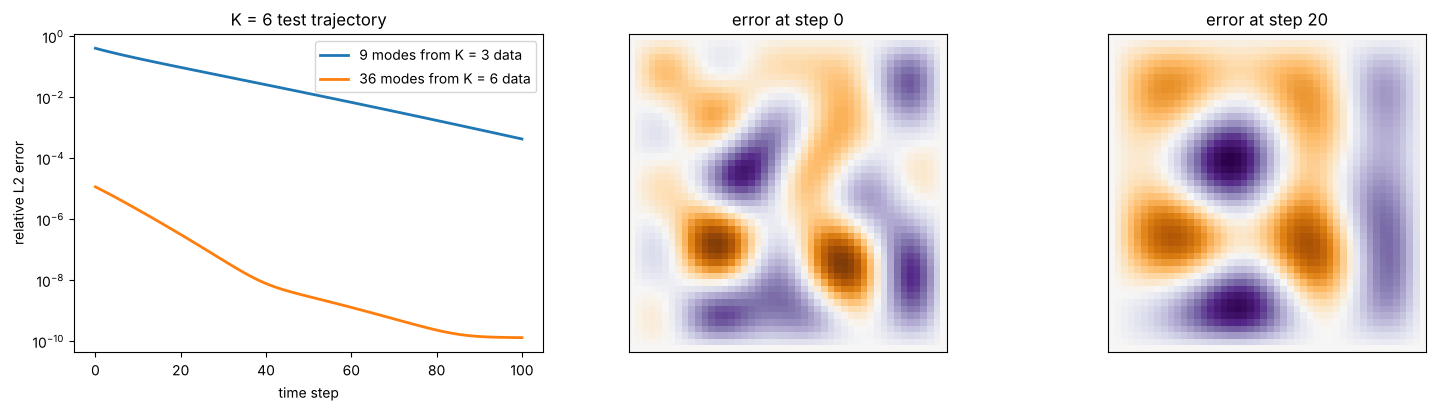

|projection of the step-0 error on sin(m pi x) sin(n pi y)|, rows n = 1..6, columns m = 1..6 (relative to the largest):
[[0.   0.   0.   1.   0.56 0.25]
 [0.   0.   0.   0.06 0.39 0.1 ]
 [0.   0.   0.   0.34 0.66 0.41]
 [0.81 0.63 0.14 0.   0.24 0.02]
 [0.55 0.09 0.21 0.13 0.55 0.24]
 [0.15 0.18 0.08 0.2  0.04 0.  ]]


In [11]:
heat3 = np.stack([heat_trajectory(K=3) for _ in range(3)])[:, 1:].reshape(-1, N, N)[:250]
m3, U3, S3 = pod(heat3)
print("K = 3 singular values, normalized:", np.round(S3[:12] / S3[0], 6))
traj = heat_test64[0]
r = 9
err_t = [relative_error(reconstruct(u, m3, U3, r), u) for u in traj]
err_t6 = [relative_error(reconstruct(u, heat_mean, heat_U, 36), u) for u in traj]     # K = 6 modes from Part 2, for comparison

fig, ax = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
ax[0].semilogy(np.arange(T + 1), err_t, lw=2, label="9 modes from K = 3 data")
ax[0].semilogy(np.arange(T + 1), err_t6, lw=2, label="36 modes from K = 6 data")
ax[0].set_xlabel("time step"); ax[0].set_ylabel("relative L2 error"); ax[0].legend(); ax[0].set_title("K = 6 test trajectory")
for a, n in zip(ax[1:], [0, 20]):
    resid = traj[n] - reconstruct(traj[n], m3, U3, r)
    v = np.abs(resid).max()
    a.imshow(resid, cmap="PuOr_r", vmin=-v, vmax=v, origin="lower"); a.set_title(f"error at step {n}"); a.set_xticks([]); a.set_yticks([])
plt.show()

# which sine modes carry the error at step 0: project the residual on sin(m pi x) sin(n pi y)
resid = traj[0] - reconstruct(traj[0], m3, U3, r)
coef = np.array([[np.sum(resid * np.sin(m * np.pi * X) * np.sin(n * np.pi * Y)) for m in range(1, 7)] for n in range(1, 7)])
print("|projection of the step-0 error on sin(m pi x) sin(n pi y)|, rows n = 1..6, columns m = 1..6 (relative to the largest):")
print(np.round(np.abs(coef) / np.abs(coef).max(), 2))

**Answer.** The `K = 3` snapshots span 9 dimensions (the singular values reach round-off after 9): the 9 sine modes with $m, n \le 3$. The reconstruction error comes entirely from the modes with $m > 3$ or $n > 3$; the projection of the error is zero in the top-left 3 × 3 block of the table.

The error is largest at the start (about 40%) and decreases with time, because those modes decay fastest (the rate is proportional to $m^2 + n^2$). In space, the error is fine-scale at step 0 and coarser at step 20, after the fastest modes have decayed. This is the same reason the `K = 3` CNN in Lecture 1 does poorly on `K = 6`: neither has seen the high-frequency modes.

### Exercise 4: standardized increment for BubbleML

The Lecture 1 BubbleML model (inputs $T, v_x, v_y$; trained on 100 and 106 °C, 40 epochs, batch 16) with and without the standardized increment.
Each input channel is standardized with its own mean and std; the increment of $T$ uses its own mean and std.

std of T 0.095   std of ΔT 0.053   ratio 56%


epoch  1   loss 2.64e-03


epoch  2   loss 2.11e-03


epoch  3   loss 1.90e-03


epoch  4   loss 1.75e-03


...

epoch 38   loss 9.32e-04


epoch 39   loss 9.26e-04


epoch 40   loss 9.18e-04


Lecture 1 model          one-step error on 103 °C 0.3541   rollout error at step 20: 0.612   at step 80: 0.526


standardized increment   one-step error on 103 °C 0.3437   rollout error at step 20: 0.703   at step 80: 0.856


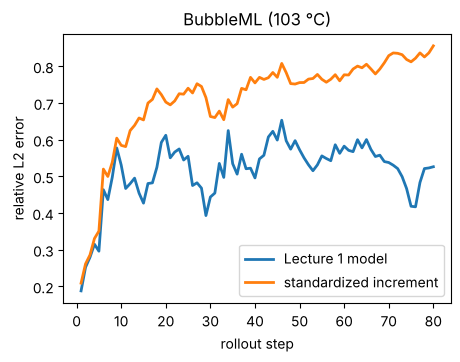

In [12]:
def load_fields(twall, keys=("temperature", "velx", "vely")):
    with h5py.File(os.path.join(DATA_DIR, f"Twall-{twall}.hdf5"), "r") as h:
        return np.stack([h[k][:] for k in keys], axis=1).astype(np.float32)          # (time, 3, y, x)

if not os.path.exists(os.path.join(DATA_DIR, "Twall-103.hdf5")):
    urllib.request.urlretrieve(URL + "Twall-103.hdf5", os.path.join(DATA_DIR, "Twall-103.hdf5"))
train_fields = [load_fields(100), load_fields(106)]
test_fields = load_fields(103)
bx = np.concatenate([a[:-1] for a in train_fields]); by = np.concatenate([a[1:, :1] for a in train_fields])
dT = by[:, 0] - bx[:, 0]
print(f"std of T {bx[:, 0].std():.3f}   std of ΔT {dT.std():.3f}   ratio {dT.std() / bx[:, 0].std():.0%}")

class BubbleCNN(SmallCNN):
    # Lecture 1 BubbleML model; with stats, standardized inputs (per channel) and standardized increment
    def __init__(self, stats=None):
        super().__init__(in_channels=3, hidden=64)
        self.stats = stats
        if stats is not None:
            mu, sd, mu_d, sd_d = stats
            self.register_buffer("mu", torch.tensor(mu).view(1, 3, 1, 1)); self.register_buffer("sd", torch.tensor(sd).view(1, 3, 1, 1))
            self.mu_d, self.sd_d = float(mu_d), float(sd_d)

    def forward(self, x):
        if self.stats is None:
            return x[:, :1] + self.net(x)
        return x[:, :1] + self.mu_d + self.sd_d * self.net((x - self.mu) / self.sd)

bstats = (bx.mean(axis=(0, 2, 3)), bx.std(axis=(0, 2, 3)), dT.mean(), dT.std())
bloader = DataLoader(TensorDataset(torch.from_numpy(bx), torch.from_numpy(by)), batch_size=16, shuffle=True)
torch.manual_seed(0); b_plain = train(BubbleCNN(), bloader, epochs=40)
torch.manual_seed(0); b_std = train(BubbleCNN(bstats), bloader, epochs=40)

@torch.no_grad()
def bubble_eval(model, start=20, steps=80):
    model.eval()
    x = torch.from_numpy(test_fields[:-1]).to(device)
    one = relative_error(model(x).cpu().numpy()[:, 0], test_fields[1:, 0])
    temp = torch.from_numpy(test_fields[start:start + 1, :1]).to(device); errs = []
    for n in range(start, start + steps):
        temp = model(torch.cat([temp, torch.from_numpy(test_fields[n:n + 1, 1:]).to(device)], dim=1))
        errs.append(relative_error(temp.cpu().numpy()[0, 0], test_fields[n + 1, 0]))
    return one, np.array(errs)

plt.figure(figsize=(5, 3.5))
for name, m in [("Lecture 1 model", b_plain), ("standardized increment", b_std)]:
    one, errs = bubble_eval(m)
    print(f"{name:24s} one-step error on 103 °C {one:.4f}   rollout error at step 20: {errs[19]:.3f}   at step 80: {errs[-1]:.3f}")
    plt.plot(np.arange(1, 81), errs, lw=2, label=name)
plt.xlabel("rollout step"); plt.ylabel("relative L2 error"); plt.title("BubbleML (103 °C)"); plt.legend(); plt.show()

**Answer.** We should not expect a large difference. For the heat data the increment was about 2% of the field, so without standardization the network had to output numbers about 50 times smaller than its input. For BubbleML the increment is 56% of the field, so the output is already of order one.

In this run the standardized model's one-step error is slightly lower (0.34 against 0.35), and its rollout is worse. Rollouts differ from seed to seed, so this difference in the rollout is not meaningful. Standardizing the increment matters when the change per step is small compared with the field.